약효분류군 - 성분코드 매핑 데이터

1. nhis 국민건강보험공단 데이터 : 급여항목만 제공
https://www.data.go.kr/data/15128709/fileData.do?recommendDataYn=Y
2. 건강보험심사평가원 : atc 매핑 테이블 = 식약처분류코드 (보건복지부 약효분류코드 아님)
https://docs.google.com/spreadsheets/d/19u-mKb0u6V_mPMFCc8yfGNEQJSTXyV1F2HyAB3aTFPc/edit?gid=1200370600#gid=1200370600
3. 건강보험심사평가원 : 매핑 관계모르면 억회불가
https://www.data.go.kr/data/15021027/openapi.do?recommendDataYn=Y
4. 빅데이터플랫폼 : 사용신청 어렵넨
https://hcdl.mohw.go.kr/static/data/dataApplyStep
5. 약제 급여 목록표 : got cha!!!! 분류번호 type = int  ***

https://www.hira.or.kr/bbsDummyKR.do?pgmid=HIRAA030014050000&brdScnBltNo=4&brdBltNo=1706&pageIndex=1&pageIndex2=1#none


## nhis 국민건강보험공단(급여)
[항목] 2018년 1월 ~ 2026년 5월 전체 급여 의약품의 월별 청구 건수, 환자 수 및 총 금액(26.8월 심사완료분까지 반영, 26.9.30. 기준)
[구분] 처방년도·월, 주성분코드(성분단위, 4자리), 연령대(10세 단위), 성별, 지역(시도), 요양기관그룹, 원내·원외처방

* STD_YYYYMM (기준년월)
	• 데이터가 수집되거나 집계된 기준 연도와 월을 의미합니다. (예: 202603 → 2026년 3월)
* WK_COMPN_4 (주요 구성 변수 / 주성분 4)
	• 데이터셋에 따라 상세 정의는 다르나, 일반적으로 분석을 위해 범주를 4가지 항목으로 분류한 주요 분류 코드를 뜻합니다.
* AGE_G (연령대 코드)
	• 환자의 나이를 10세 단위 등으로 묶은 연령대 그룹입니다. (예: 1대인 경우 0~9세 등)
* SEX_TYPE (성별)
	• 환자의 성별을 구분하는 코드입니다. (보통 1: 남성, 2: 여성)
* SIDO (시도 코드)
	• 환자의 거주지 또는 의료기관이 위치한 시/도 행정구역을 나타냅니다. (예: 11 서울, 41 경기 등)
* YOYANG_CLSFC_CD_ADJ (요양기관 분류 코드 정비/보정)
	• 병원, 의원, 약국 등 의료기관의 종류를 나타내는 요양기관 분류 코드를 분석용으로 재분류하거나 정비한 코드입니다.
* OUT_IN_HOS (외래/입원 구분)
	• 환자가 병원에 입원했는지, 아니면 외래 진료를 받았는지 구분하는 코드입니다.
* PRSCRPTN_TNDN_CNT (처방 건수 / 처방전 수)
	• 실제로 발행된 총 처방전의 개수를 의미합니다.
* PRSCRPTN_AMT (처방 금액)
	• 처방된 의약품이나 진료의 총 처방 약제비/금액을 뜻합니다.
* PATIENT_CNT (환자 수)
	• 해당 억건에 해당하는 실제 환자의 수(중복을 제거한 명수)를 의미합니다.
* PRSCRPTN_TOT_USE (총 처방 사용량 / 총 복용량)
	• 처방된 의약품의 일수와 수량을 모두 곱한 전체 의약품 사용량(수량)을 의미합니다.


## Data description

1. 샘플에서 PRSCRPTN_AMT / PRSCRPTN_TOT_USE가 약 195~203원으로 일정합니다. 그래서 PRSCRPTN_TOT_USE는 투약일수와 일 투여량을 곱한 수량 단위(정·캡슐 수 등)로 보이며, 단가 분해에 쓸 수 있습니다. 같은 성분 코드 안에서는 단위당 금액이 거의 일정하다는 뜻이기도 합니다.

2. 환자수는 합산할 수 없습니다.
PATIENT_CNT는 셀(월×성분×연령×성별×...×시도×기관×원내외) 안의 고유 환자수입니다.

* 한 환자가 여러 성분, 기관, 지역에서 처방받으면 셀을 합칠 때 중복 집계됩니다.
월별 환자수를 합친 값은 고유 환자수가 아니라 **환자-월(연인원)**입니다.
따라서 "연간 환자수"처럼 쓰지 말고 "월평균 환자수"나 "환자-월"로 정의해서 일관되게 쓰세요.

3. 한 약효분류군 안에서 성분 간 대체가 일어납니다.
복합제는 별도 4자리 코드를 갖는 경우가 많습니다. 분류군 전체 성장과 성분 간 점유율 이동(신규 성분, 복합제 전환 등)을 구분해서 봐야 합니다.

In [ ]:
target_gen4__df = pd.read_csv('../data/cmpn4_list.csv',index=False)

# 분석 범위
## target drug : cluster name  - meft no - generic code [first4 digit]

## 1. 성장 요인 분해 (가장 핵심)
처방금액은 다음과 같이 쪼갤 수 있습니다.

> **처방금액 = 환자수 × (환자당 처방건수) × (건당 투약량) × (투약단위당 금액)**

| 지표 | 계산 | 해석 |
|---|---|---|
| 환자 수 | `PATIENT_CNT` | 신규 환자 유입, 시장 저변 확대 |
| 환자당 처방건수 | `PRSCRPTN_TNDN_CNT / PATIENT_CNT` | 내원/재처방 빈도 |
| 건당 투약량 | `PRSCRPTN_TOT_USE / PRSCRPTN_TNDN_CNT` | 장기처방화, 용량 증가 |
| 단위당 금액 | `PRSCRPTN_AMT / PRSCRPTN_TOT_USE` | 약가, 고가 성분으로의 믹스 변화 |
| 환자당 금액 | `PRSCRPTN_AMT / PATIENT_CNT` | 환자당 약제비 변화 |

성장이 환자 수 증가(볼륨)에서 나오는지, 장기처방이나 단가 상승(집약도·믹스)에서 나오는지 구분됩니다. 로그 분해(LMDI)나 기여도(%p) 방식으로 정량화할 수 있습니다.

## 2. 성분(4자리 코드)별 성장 기여도
- 약효분류군 내 각 성분의 **성장 기여도** (성분별 증가액 ÷ 분류군 전체 증가액)
- 성분별 **점유율 변화**(금액·환자수·사용량 기준)와 CAGR
- 성장 주도 성분과 정체·감소 성분 식별, HHI 등 집중도 변화
- 신규 진입 성분(기준기간 초반 0, 이후 급증)의 포착

## 3. 세그먼트별 성장 분석
- **연령·성별**: 어느 연령대가 성장을 이끄는지, 고령화 효과 대 처방 확대 효과 구분
- **지역(시도)**: 지역별 침투율 차이, 성장 격차
- **요양기관 종별**: 상급종합·의원·약국 등 처방 채널 이동 (예: 상급병원 → 의원으로 확산)
- **외래/입원**: 처방 패턴 변화

세그먼트별로 "성장률 × 비중"을 보면 성장이 넓게 퍼진 것인지, 특정 세그먼트에 집중된 것인지 알 수 있습니다.

## 4. 시계열 분석
- 월 데이터이므로 YoY, 이동평균, **계절성**(예: 호흡기·알레르기 계열)
- 급여 확대, 약가 인하, 가이드라인 변경, 코로나 시기 등 **이벤트 전후 변화**
- 3년 연속 초과성장이 일관된 추세인지, 일회성 이벤트 영향인지 확인

## 5. 시장 대비 초과성장 검증
데이터가 전체 성분을 포함한다면, 전체 시장 합계를 직접 계산해 **초과성장 기준을 재현**하고 지표별(금액·환자수·사용량)로 따로 비교할 수 있습니다. 금액 기준으로는 초과성장이지만 사용량 기준으로는 아닐 수도 있습니다.

## 한계와 주의사항
- **제품(브랜드)·제억사·적응증(상병) 정보가 없습니다.** 성분 단위까지만 분석 가능하고, 오리지널/제네릭 구분이나 성장 이유(질환별)는 알 수 없습니다.
- **`PATIENT_CNT`는 합산 불가**입니다. 환자가 여러 성분·지역·월에 걸쳐 중복되므로, 세그먼트 합이 전체와 다릅니다. 환자수는 집계 레벨 그대로 해석해야 합니다.
- 금액에는 **약가 인하·급여기준 변경** 효과가 섞여 있어, 사용량 기준과 병행해서 봐야 합니다.
- 연령·지역으로 세분화할수록 작은 셀의 값이 마스킹되거나 불안정할 수 있습니다.

## 권장 진행 순서
1. 분류군 전체 월별 추이 + 시장 대비 성장 검증
2. 환자수/건수/투약량/단가 분해로 성장 성격 파악
3. 4자리 성분별 기여도로 성장 동력 성분 식별
4. 해당 성분에 대해서만 연령·지역·기관종별로 드릴다운


In [1]:
import pandas as pd
import duckdb
from pathlib import Path

Path("work").mkdir(exist_ok=True)
con = duckdb.connect("work/nhis.duckdb")
con.sql("SET memory_limit='8GB'")                # PC 사양에 맞게 조정
con.sql("SET temp_directory='work/duck_tmp'")    # 메모리 초과 시 디스크로 spill
con.sql("SET threads=4")

In [57]:
gen4_codes_df = pd.read_csv('../data/target_cmpn4_map.csv')

# 최초 1회만 실행
table_name = 'meft_generic_map'
con.register('tmp_meft_generic_map', gen4_codes_df)
# con.sql("""
#     DROP VIEW meft_generic_map ;
# """)
con.sql("""
    CREATE OR REPLACE TABLE meft_generic_map AS
    SELECT DISTINCT WK_COMPN_4, 분류 as meft_no, category
    FROM tmp_meft_generic_map;
""")
con.unregister('tmp_meft_generic_map')
print(con.sql("SELECT * FROM meft_generic_map LIMIT 5").df())
# n = con.sql(f"SELECT COUNT(*) FROM {table_name}").fetchone()[0]
# print(f"✅ {table_name} 등록 완료: {n}행")


   WK_COMPN_4  meft_no           category
0        1858      218  HS_CONT_OUTGROWTH
1        7070      421  HS_CONT_OUTGROWTH
2        6248      421  HS_CONT_OUTGROWTH
3        1650      218  HS_CONT_OUTGROWTH
4        7402      629   HS_Y25_OUTGROWTH


In [9]:
temp_df = con.sql("""
    
        SELECT 
        *
        FROM grp 
    ORDER BY STD_YYYYMM
""").df()
print(temp_df.shape)
temp_df.head()

(3950191, 12)


,STD_YYYYMM,year,WK_COMPN_4,AGE_G,SEX_TYPE,SIDO,YOYANG_CLSFC_CD_ADJ,OUT_IN_HOS,PATIENT_CNT,PRSCRPTN_TNDN_CNT,PRSCRPTN_AMT,PRSCRPTN_TOT_USE
0,201901,2019,2408,60,2,42,1,OUT,1,1,2192.0,1.0
1,201901,2019,1673,60,2,50,1,IN,1,1,8200.0,1.0
2,201901,2019,2357,60,2,50,1,IN,1,1,3585.0,1.0
3,201901,2019,6409,60,2,31,1,IN,1,1,1263.0,1.0
4,201901,2019,4633,60,2,44,1,IN,1,1,481156.0,1.0


In [14]:
rolling_df = con.sql("""
    WITH monthly AS (
        SELECT
            STRPTIME(STD_YYYYMM, '%Y%m')::DATE AS ym,
            SUM(PRSCRPTN_AMT)      AS amt,
            SUM(PRSCRPTN_TOT_USE)  AS use_qty
        FROM grp
        GROUP BY 1
    ),
    rolling AS (
        SELECT
            ym,
            amt,
            use_qty,
            SUM(amt)     OVER w12 AS amt_roll12,
            SUM(use_qty) OVER w12 AS use_roll12,
            ROW_NUMBER() OVER (ORDER BY ym) AS rn
        FROM monthly
        WINDOW w12 AS (
            ORDER BY ym
            ROWS BETWEEN 11 PRECEDING AND CURRENT ROW
        )
    )
    SELECT
        ym,
        amt,
        use_qty,
        CASE WHEN rn >= 12 THEN amt_roll12 END AS amt_roll12,
        CASE WHEN rn >= 12 THEN use_roll12 END AS use_roll12,
        CASE WHEN rn >= 12 THEN
            amt_roll12::DOUBLE
              / NULLIF(LAG(amt_roll12, 12) OVER (ORDER BY ym), 0) - 1
        END AS amt_roll12_yoy
    FROM rolling
    ORDER BY ym
""").df()

rolling_df.tail(4)

,ym,amt,use_qty,amt_roll12,use_roll12,amt_roll12_yoy
80,2025-09-01,4.783006e+11,4.981232e+08,5.192755e+12,5.323169e+09,0.075445
81,2025-10-01,4.243036e+11,4.386303e+08,5.191429e+12,5.322882e+09,0.068237
82,2025-11-01,4.340767e+11,4.493100e+08,5.218500e+12,5.352897e+09,0.071490
83,2025-12-01,4.781057e+11,4.946516e+08,5.261931e+12,5.397406e+09,0.070861


In [15]:
print(rolling_df.dtypes)
print(rolling_df.tail())

ym                datetime64[us]
amt                      float64
use_qty                  float64
amt_roll12               float64
use_roll12               float64
amt_roll12_yoy           float64
dtype: object
           ym           amt       use_qty    amt_roll12    use_roll12  \
79 2025-08-01  4.321337e+11  4.438136e+08  5.113026e+12  5.235927e+09   
80 2025-09-01  4.783006e+11  4.981232e+08  5.192755e+12  5.323169e+09   
81 2025-10-01  4.243036e+11  4.386303e+08  5.191429e+12  5.322882e+09   
82 2025-11-01  4.340767e+11  4.493100e+08  5.218500e+12  5.352897e+09   
83 2025-12-01  4.781057e+11  4.946516e+08  5.261931e+12  5.397406e+09   

    amt_roll12_yoy  
79        0.064870  
80        0.075445  
81        0.068237  
82        0.071490  
83        0.070861  


In [40]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns


plt.rc('font', family='NanumGothic')  # Windows
plt.rcParams['axes.unicode_minus'] = False

### 1. trend and momentum

In [47]:
def plot_panel1(ax1, d, partial):
    """월별 vs 12M 롤링 — 조 단위 표시"""
    from matplotlib.ticker import FuncFormatter

    amt_jo  = d['amt'] / 1e12
    roll_jo = d['amt_roll12'] / 1e12

    # 월별 (막대)
    ax1.bar(d['ym'], amt_jo, width=20,
            color='#B0C4DE', label='월별 매출')
    # ax1.set_ylabel('월별 매출 (조 원)') #, color='#4A6FA5'
    ax1.tick_params(axis='y', labelcolor='#4A6FA5')

    # 롤링 (라인)
    ax2 = ax1.twinx()
    ax2.plot(d.loc[~partial,'ym'], roll_jo[~partial],
             color='#D62728', lw=2.5, label='12M 롤링')
    ax2.plot(d.loc[partial,'ym'], roll_jo[partial],
             color='gray', ls=':', lw=1.5, label='부분합(신뢰 불가)')
    # ax2.set_ylabel('12M 롤링 (조 원)') #, color='#D62728'
    ax2.tick_params(axis='y', labelcolor='#D62728')

    # 눈금 포맷
    fmt = FuncFormatter(lambda v, _: f'{v:,.1f}조')
    ax1.yaxis.set_major_formatter(fmt)
    ax2.yaxis.set_major_formatter(fmt)

    # 마지막 값 강조
    last = d.iloc[-1]
    ax2.annotate(f'{last["amt_roll12"]/1e12:.2f}조',
                 xy=(last['ym'], last['amt_roll12']/1e12),
                 xytext=(-50, 10), textcoords='offset points',
                 color='#D62728', fontsize=10, fontweight='bold')

    # 범례 통합
    h1, l1 = ax1.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax1.legend(h1 + h2, l1 + l2, loc='upper left', fontsize=8)

    ax1.set_title('① 월별 매출 vs 12M 롤링 (단위: 조 원)')
    
def plot_trend():

    plt.close('all')
    plt.rcParams['axes.unicode_minus'] = False
    

    d = rolling_df.copy()
    d['ym'] = pd.to_datetime(d['ym'])
    d = d.sort_values('ym').reset_index(drop=True)
    if 'rn' not in d.columns:
        d['rn'] = d.index + 1
    partial = d['rn'] < 12

    recent = d[d['ym'] >= '2021-01-01'].copy()
    yoy = recent['amt_roll12_yoy'] * 100

    fig, axes = plt.subplots(2, 2, figsize=(16, 10))

    # ── ① 월별 + 롤링 ─────────────────────
    ax1 = axes[0,0]
    plot_panel1(ax1, d, partial)
    # ax1.bar(d['ym'], d['amt'], width=20, color='#B0C4DE')
    # ax2 = ax1.twinx()
    # ax2.plot(d.loc[~partial,'ym'], d.loc[~partial,'amt_roll12'],
    #          color='#D62728', lw=2.5, label='12M 롤링')
    # ax2.plot(d.loc[partial,'ym'], d.loc[partial,'amt_roll12'],
    #          color='gray', ls=':', lw=1.5, label='부분합(신뢰 불가)')
    # ax1.set_title('① 월별 매출 vs 12M 롤링')
    # ax2.legend(loc='upper left', fontsize=8)


    # ── ② 롤링 YoY — 정상 축 + 음영 ─────────
    ax = axes[0,1]
    ax.plot(recent['ym'], yoy, lw=2.5, color='#1f77b4',
            marker='o', ms=4)
    ax.set_ylim(yoy.min()-2, yoy.max()+2)
    ax.axhline(10, color='green', ls='--', lw=1.2, label='목표 +10%')
    ax.axhline(0,  color='black', lw=1)
    ax.fill_between(recent['ym'], 10, yoy, where=(yoy>=10),
                    color='green', alpha=0.15, label='목표 초과')
    ax.fill_between(recent['ym'], 10, yoy, where=(yoy<10),
                    color='red', alpha=0.12, label='목표 미달')

    imax = yoy.idxmax(); imin = yoy.idxmin()
    for idx, txt, c, off in [(imax,'Peak','green',(10,15)),
                             (imin,'Trough','red',(10,-30))]:
        ax.scatter(recent.loc[idx,'ym'], yoy.loc[idx],
                   color=c, s=80, zorder=5)
        ax.annotate(f"{txt} {yoy.loc[idx]:.1f}%\n{recent.loc[idx,'ym']:%Y-%m}",
                    xy=(recent.loc[idx,'ym'], yoy.loc[idx]),
                    xytext=off, textcoords='offset points',
                    color=c, fontsize=9,
                    arrowprops=dict(arrowstyle='->', color=c))
    ax.set_ylabel('YoY (%)')
    ax.set_title('② 롤링 YoY — 목표 대비')
    ax.legend(fontsize=8, loc='lower left')
    ax.grid(alpha=0.3)

    # ── ③ 성장 모멘텀 ──────────────────────
    ax = axes[1,0]
    momentum = yoy.diff(3)
    colors = ['green' if v>=0 else 'red' for v in momentum]
    ax.bar(recent['ym'], momentum, width=20, color=colors)
    ax.axhline(0, color='black', lw=1)
    turning = recent[(momentum.shift(1)>0) & (momentum<0)]
    for _, r in turning.iterrows():
        ax.axvline(r['ym'], color='orange', ls='--', alpha=0.6)
    ax.set_ylabel('3개월 기울기 (%p)')
    ax.set_title('③ 성장 모멘텀 (양수=가속, 음수=둔화)')
    ax.grid(alpha=0.3)

    # ── ④ 히트맵 ───────────────────────────
    ax = axes[1,1]
    hm_src = d[d['ym'].dt.year >= 2021].copy()
    hm_src['year']  = hm_src['ym'].dt.year
    hm_src['month'] = hm_src['ym'].dt.month
    hm = hm_src.pivot_table(index='year', columns='month',
                            values='amt_roll12_yoy', aggfunc='mean') * 100
    sns.heatmap(hm, annot=True, fmt='.1f', cmap='RdYlGn',
                center=0, vmin=-20, vmax=30, ax=ax, cbar=False)
    ax.set_title('④ 연도×월 YoY (%) — 2022 정점, 2025 둔화')

    plt.tight_layout()
    plt.show()

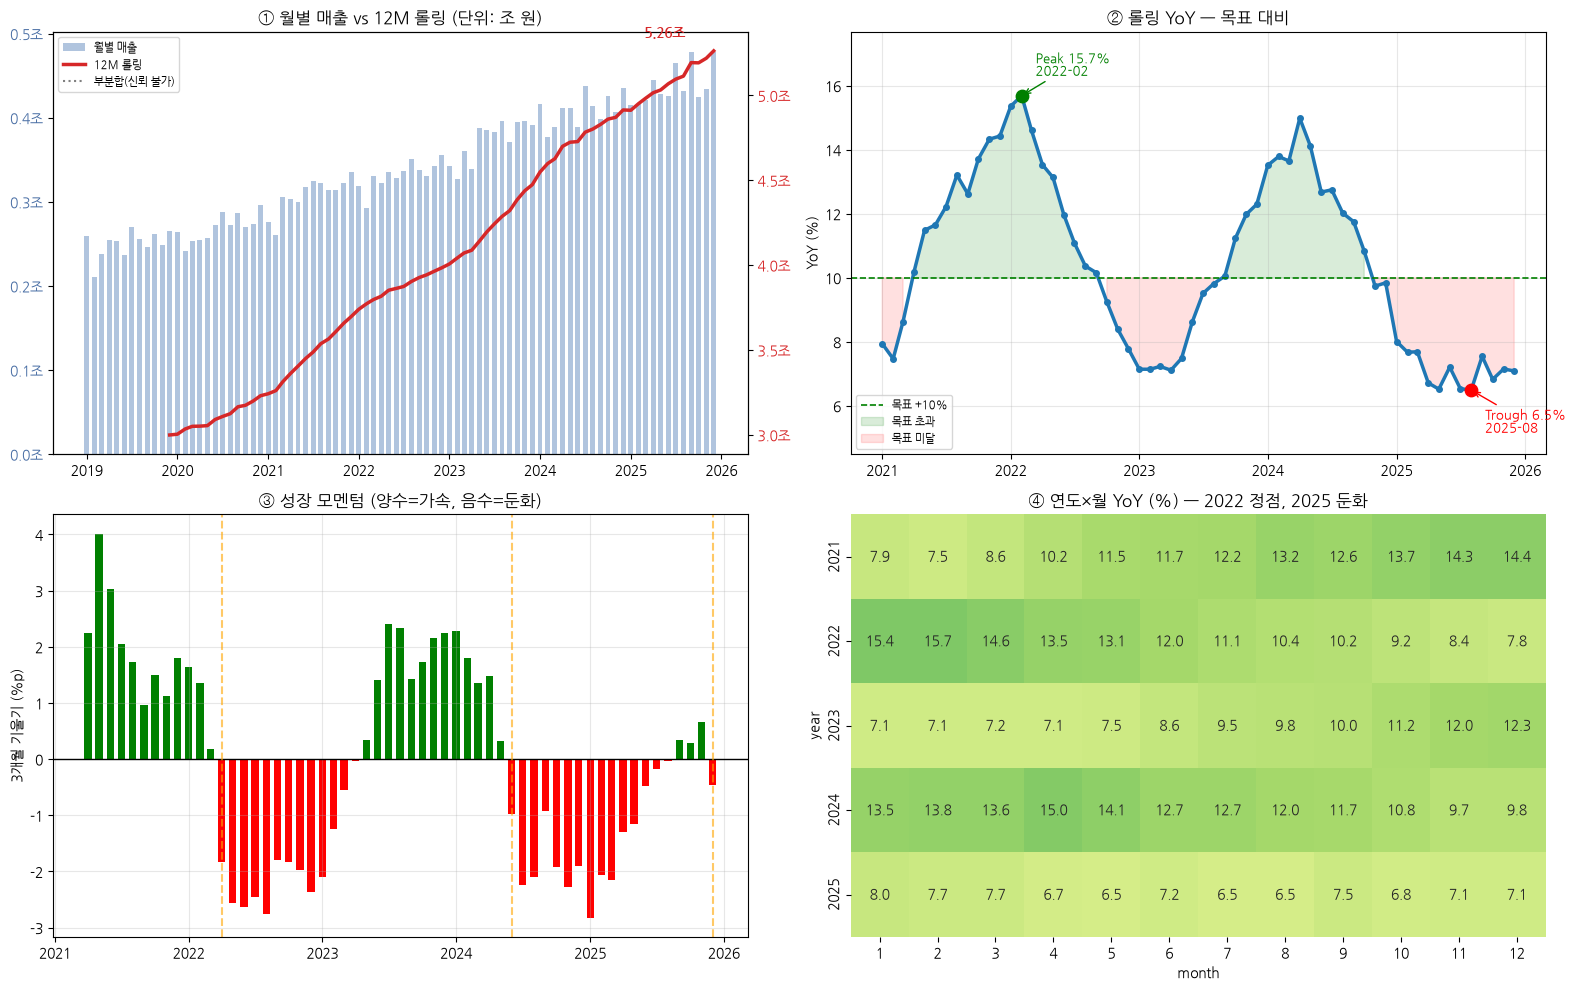

In [48]:
plot_trend()

# import matplotlib.font_manager as fm
# print(fm.get_cached_fonts())

### 3. contribution by generic within meft 

In [ ]:
contrib_meft_ing = con.sql("""
    WITH j AS (
        SELECT g.year, m.meft_no, g.WK_COMPN_4,
               SUM(g.PRSCRPTN_AMT) AS amt
        FROM grp g
        JOIN meft_generic_map m USING (WK_COMPN_4)
        GROUP BY g.year, m.meft_no, g.WK_COMPN_4
    ),
    -- 성분 × 연도 그리드: 누락 연도를 0으로 채움
    grid AS (
        SELECT i.meft_no, i.WK_COMPN_4, y.year,
               COALESCE(j.amt, 0) AS amt
        FROM (SELECT DISTINCT meft_no, WK_COMPN_4 FROM j) i
        CROSS JOIN (SELECT DISTINCT year FROM j) y
        LEFT JOIN j
          ON  j.meft_no   = i.meft_no
          AND j.WK_COMPN_4 = i.WK_COMPN_4
          AND j.year       = y.year
    ),
    t AS (
        SELECT meft_no, year,
               SUM(amt) AS tot,
               LAG(SUM(amt)) OVER (PARTITION BY meft_no ORDER BY year) AS tot_prev
        FROM grid
        GROUP BY meft_no, year
    )
    SELECT
        grid.meft_no, grid.WK_COMPN_4, grid.year, grid.amt,
        t.tot       AS meft_tot,
        t.tot_prev  AS meft_tot_prev,
        grid.amt - LAG(grid.amt) OVER w AS delta,
        (grid.amt - LAG(grid.amt) OVER w)
            / NULLIF(t.tot_prev, 0)     AS contrib_in_meft_pp,
        grid.amt / NULLIF(t.tot, 0)     AS share_in_meft
    FROM grid
    JOIN t USING (meft_no, year)
    WINDOW w AS (
        PARTITION BY grid.meft_no, grid.WK_COMPN_4
        ORDER BY grid.year
    )
    ORDER BY grid.meft_no, grid.year, contrib_in_meft_pp DESC NULLS LAST
""").df()

chk = (contrib_meft_ing
       .dropna(subset=['contrib_in_meft_pp'])
       .groupby(['meft_no', 'year'])['contrib_in_meft_pp']
       .sum()
       .rename('contrib_sum')
       .reset_index())

actual = con.sql("""
    SELECT g.year, m.meft_no,
           SUM(g.PRSCRPTN_AMT)
             / LAG(SUM(g.PRSCRPTN_AMT))
                 OVER (PARTITION BY m.meft_no ORDER BY g.year)
             - 1 AS growth
    FROM grp g JOIN meft_generic_map m USING (WK_COMPN_4)
    GROUP BY g.year, m.meft_no
""").df()

merged = chk.merge(actual, on=['meft_no','year'])
merged['diff'] = (merged['contrib_sum'] - merged['growth']).abs()

print("검증 실패 행 (diff > 1e-6):")
print(merged[merged['diff'] > 1e-6])
print(f"\n실패 행 수: {(merged['diff'] > 1e-6).sum()} / {len(merged)}")
print(f"최대 오차: {merged['diff'].max():.2e}")
contrib_meft_ing.head()

검증 실패 행 (diff > 1e-6):
Empty DataFrame
Columns: [meft_no, year, contrib_sum, growth, diff]
Index: []

실패 행 수: 0 / 41
최대 오차: 1.11e-16


In [69]:
meft_all = con.sql("""
    SELECT DISTINCT meft_no
    FROM meft_generic_map
    ORDER BY meft_no
""").df()['meft_no'].tolist()

print(f"분석 대상 약효분류군: {len(meft_all)}개")
print(meft_all)

last_year = int(contrib_meft_ing['year'].max())

summary = (contrib_meft_ing
           [contrib_meft_ing['year'] == last_year]
           .groupby('meft_no')
           .agg(
               meft_tot=('meft_tot', 'first'),         # 분류군 총액
               n_codes=('WK_COMPN_4', 'nunique'),      # 성분 수
               top1_share=('share_in_meft', 'max'),    # 최대 성분 점유율
               hhi=('share_in_meft', lambda s: (s**2).sum()),  # 집중도
           )
           .loc[meft_all]
           .sort_values('meft_tot', ascending=False))

print("@last year : \n ",summary.round(4))

분석 대상 약효분류군: 7개
[218, 235, 249, 421, 429, 612, 629]
@last year : 
               meft_tot  n_codes  top1_share     hhi
meft_no                                           
218      3.424445e+12       31      0.1695  0.0951
421      1.063651e+12       41      0.1249  0.0606
629      5.797239e+11       19      0.1792  0.1179
235      9.559062e+10        5      0.5493  0.3764
249      7.567887e+10        1      1.0000  1.0000
612      1.340288e+10        2      0.5117  0.5003
429      9.439073e+09        1      1.0000  1.0000


findfont: Failed to find font weight bold for NanumGothic, now using 600.
findfont: Failed to find font weight bold for NanumGothic, now using 600.


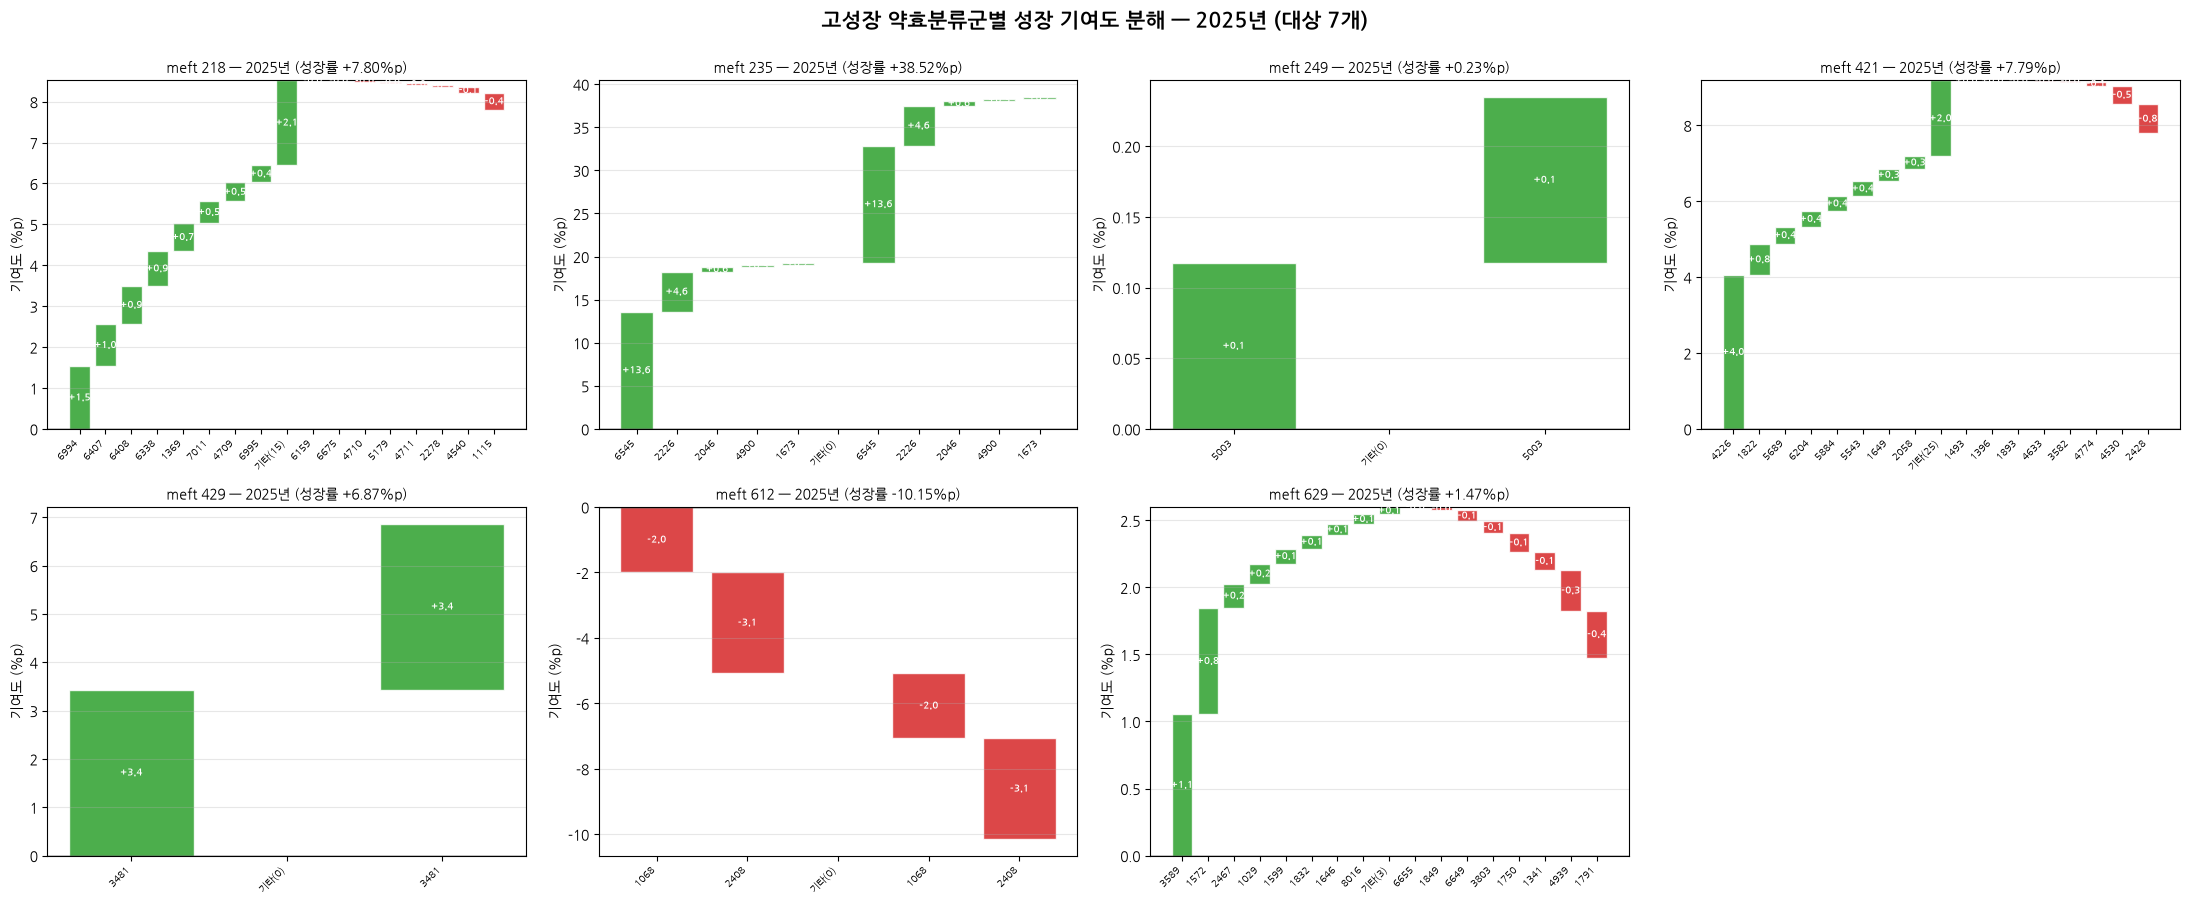

In [70]:
import matplotlib.pyplot as plt
import pandas as pd

def waterfall_meft(target_meft, target_year, top_n=8, ax=None):
    sub = (contrib_meft_ing
           [(contrib_meft_ing['meft_no'] == target_meft) &
            (contrib_meft_ing['year'] == target_year)]
           .dropna(subset=['contrib_in_meft_pp'])
           .copy())

    sub = sub.sort_values('contrib_in_meft_pp', ascending=False)
    top_pos = sub.head(top_n)
    top_neg = sub.tail(top_n)
    others  = sub.iloc[top_n:-top_n]
    other_sum = others['contrib_in_meft_pp'].sum() if len(others) else 0.0

    plot_df = pd.concat([
        top_pos,
        pd.DataFrame([{'WK_COMPN_4': f'기타({len(others)})',
                       'contrib_in_meft_pp': other_sum}]),
        top_neg
    ]).reset_index(drop=True)

    if ax is None:
        fig, ax = plt.subplots(figsize=(13, 6))

    cum = 0
    for i, row in plot_df.iterrows():
        v = row['contrib_in_meft_pp'] * 100
        color = '#2CA02C' if v >= 0 else '#D62728'
        ax.bar(i, v, bottom=cum, color=color, alpha=0.85, edgecolor='white')
        ax.text(i, cum + v/2, f'{v:+.1f}',
                ha='center', va='center', fontsize=7,
                color='white', fontweight='bold')
        cum += v

    ax.axhline(0, color='black', lw=1)
    ax.set_xticks(range(len(plot_df)))
    ax.set_xticklabels(plot_df['WK_COMPN_4'].astype(str),
                       rotation=45, ha='right', fontsize=7)
    ax.set_ylabel('기여도 (%p)')
    ax.set_title(f'meft {target_meft} — {target_year}년 '
                 f'(성장률 {cum:+.2f}%p)', fontsize=10)
    ax.grid(axis='y', alpha=0.3)
    return cum


# 6~8개 전체를 2×4 그리드로
n = len(meft_all)
n_cols = 4
n_rows = (n + n_cols - 1) // n_cols   # ceil

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols*5.5, n_rows*4.5))
axes = axes.flatten() if n > 1 else [axes]

for i, m in enumerate(meft_all):
    waterfall_meft(m, last_year, top_n=8, ax=axes[i])

# 남는 칸 제거
for j in range(n, len(axes)):
    axes[j].axis('off')

fig.suptitle(f'고성장 약효분류군별 성장 기여도 분해 — {last_year}년 '
             f'(대상 {n}개)',
             fontsize=15, fontweight='bold', y=1.00)
plt.tight_layout(); plt.show()

In [86]:
# ─── 월별 롤링 성분 기여도 (약효분류군 내부) ─────────────
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

def waterfall_meft(target_meft, target_year, top_n=8,
                   sort_by='contrib', ax=None):
    """
    약효분류군 성장 기여도 워터폴 (연도별)
    sort_by: 'contrib' | 'share' | 'efficiency'
    """
    sub = (contrib_meft_ing
           [(contrib_meft_ing['meft_no'] == target_meft) &
            (contrib_meft_ing['year'] == target_year)]
           .dropna(subset=['contrib_in_meft_pp'])
           .copy())

    if sub.empty:
        print(f"meft {target_meft} / {target_year}: 데이터 없음")
        return None

    if sort_by == 'share':
        sub = sub.sort_values('share_in_meft', ascending=False)
    elif sort_by == 'efficiency':
        sub['eff'] = (sub['contrib_in_meft_pp']
                      / sub['share_in_meft'].replace(0, np.nan))
        sub = sub.sort_values('eff', ascending=False)

    pos = sub[sub['contrib_in_meft_pp'] > 0].nlargest(top_n, 'contrib_in_meft_pp')
    neg = sub[sub['contrib_in_meft_pp'] < 0].nsmallest(top_n, 'contrib_in_meft_pp')

    used = set(pos['WK_COMPN_4']) | set(neg['WK_COMPN_4'])
    others_sum = sub[~sub['WK_COMPN_4'].isin(used)]['contrib_in_meft_pp'].sum()

    plot_df = pd.concat([
        pos,
        pd.DataFrame([{'WK_COMPN_4': f'기타({len(sub)-len(used)})',
                       'contrib_in_meft_pp': others_sum}]),
        neg,
    ]).reset_index(drop=True)

    if ax is None:
        fig, ax = plt.subplots(figsize=(13, 6))

    cum = 0
    for i, row in plot_df.iterrows():
        v = row['contrib_in_meft_pp'] * 100
        color = '#2CA02C' if v >= 0 else '#D62728'
        ax.bar(i, v, bottom=cum, color=color, alpha=0.85, edgecolor='white')
        if abs(v) >= 0.5:
            ax.text(i, cum + v/2, f'{v:+.1f}',
                    ha='center', va='center', fontsize=7,
                    color='white', fontweight='bold')
        cum += v

    ax.axhline(0, color='black', lw=1)
    ax.set_xticks(range(len(plot_df)))
    ax.set_xticklabels(plot_df['WK_COMPN_4'].astype(str),
                       rotation=60, ha='right', fontsize=7)
    ax.set_ylabel('기여도 (%p)')
    ax.set_title(f'meft {target_meft} — {target_year}년 '
                 f'(합계 {cum:+.2f}%p)', fontsize=10)
    ax.grid(axis='y', alpha=0.3)
    return cum

import matplotlib.pyplot as plt
import numpy as np

def scatter_share_contrib(target_meft, target_year, ax=None):
    """
    점유율(x) vs 기여도(y) scatter
    - 원 크기: 매출 규모
    - 라벨: 저점유·저기여(좌하단)만 제외, 나머지 전부 표시
    """
    sub = (contrib_meft_ing
           [(contrib_meft_ing['meft_no'] == target_meft) &
            (contrib_meft_ing['year'] == target_year)]
           .dropna(subset=['share_in_meft', 'contrib_in_meft_pp'])
           .copy())

    if sub.empty:
        print(f"meft {target_meft} / {target_year}: 데이터 없음")
        return

    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 9))

    x = sub['share_in_meft'] * 100
    y = sub['contrib_in_meft_pp'] * 100
    sizes = sub['amt'] / sub['amt'].max() * 800 + 60

    colors = ['#2CA02C' if v >= 0 else '#D62728' for v in y]
    ax.scatter(x, y, s=sizes, c=colors, alpha=0.55,
               edgecolor='white', linewidth=1.2, zorder=3)

    # ─── 라벨 조건 ───────────────────────────────
    x_med = sub['share_in_meft'].median() * 100
    is_low_share  = x < x_med
    is_low_contrib = y < 0
    is_bottom_left = is_low_share & is_low_contrib

    to_label = sub[~is_bottom_left.values]   # 좌하단 제외 전부

    # 매출 큰 순으로 정렬해 겹침 시 큰 원이 위로
    to_label = to_label.sort_values('amt', ascending=False)

    for _, r in to_label.iterrows():
        xx = r['share_in_meft'] * 100
        yy = r['contrib_in_meft_pp'] * 100
        ax.annotate(
            str(r['WK_COMPN_4']),
            xy=(xx, yy),
            xytext=(0, 14), textcoords='offset points',
            fontsize=8, ha='center', va='bottom',
            color='black',
            bbox=dict(boxstyle='round,pad=0.15',
                      fc='white', ec='gray',
                      alpha=0.75, lw=0.4),
            zorder=4,
        )

    # ─── 사분면 기준선 ───────────────────────────
    ax.axhline(0, color='black', lw=1)
    ax.axvline(x_med, color='gray', ls='--', lw=1)

    # ─── 사분면 라벨 ─────────────────────────────
    xmax, xmin = x.max(), min(x.min(), 0)
    ymax = y.max() if y.max() > 0 else 1
    ymin = y.min() if y.min() < 0 else -1

    pad_x = (xmax - xmin) * 0.02
    pad_y = (ymax - ymin) * 0.04

    ax.text(xmax - pad_x, ymax - pad_y,
            '고점유·고기여\n(핵심 엔진)',
            ha='right', va='top', fontsize=9,
            color='green', alpha=0.6, style='italic')
    ax.text(xmin + pad_x, ymax - pad_y,
            '저점유·고기여\n(숨은 성장동력)',
            ha='left', va='top', fontsize=9,
            color='blue', alpha=0.6, style='italic')
    ax.text(xmax - pad_x, ymin + pad_y,
            '고점유·저기여\n(성숙/정체)',
            ha='right', va='bottom', fontsize=9,
            color='orange', alpha=0.6, style='italic')
    ax.text(xmin + pad_x, ymin + pad_y,
            '저점유·저기여\n(라벨 생략)',
            ha='left', va='bottom', fontsize=9,
            color='red', alpha=0.4, style='italic')

    # ─── 축/제목 ─────────────────────────────────
    ax.set_xlabel('점유율 (%)')
    ax.set_ylabel('기여도 (%p)')
    ax.set_title(
        f'meft {target_meft} — {target_year}년 '
        f'(n={len(sub)}, 라벨 {len(to_label)}개)\n'
        f'점유율 vs 기여도 (원 크기 = 매출)',
        fontsize=11,
    )
    ax.grid(alpha=0.3, zorder=0)

def plot_meft_share_year(target_meft, top_n=5, ax=None):
    """약효분류군 내 성분 점유율 추이 (연도별)"""
    sub = (contrib_meft_ing
           [contrib_meft_ing['meft_no'] == target_meft]
           .dropna(subset=['share_in_meft'])
           .copy())

    if sub.empty:
        print(f"meft {target_meft}: 데이터 없음")
        return

    last_year = sub['year'].max()
    top_ing = (sub[sub['year'] == last_year]
               .nlargest(top_n, 'share_in_meft')['WK_COMPN_4'].tolist())

    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 6))

    cmap = plt.get_cmap('tab10')
    for i, ing in enumerate(top_ing):
        g = sub[sub['WK_COMPN_4'] == ing].sort_values('year')
        ax.plot(g['year'], g['share_in_meft'] * 100, lw=2,
                marker='o', ms=5, color=cmap(i % 10), label=str(ing))

    # 나머지는 회색
    for ing, g in sub.groupby('WK_COMPN_4'):
        if ing not in top_ing:
            g = g.sort_values('year')
            ax.plot(g['year'], g['share_in_meft'] * 100,
                    lw=0.6, color='lightgray', alpha=0.4)

    ax.set_ylabel('점유율 (%)')
    ax.set_xlabel('연도')
    ax.set_title(f'meft {target_meft} 내 성분 점유율 추이 (Top {top_n})',
                 fontsize=10)
    ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1))
    ax.grid(alpha=0.3)
    ax.set_xticks(sorted(sub['year'].unique()))


def heatmap_contrib_year(target_meft, top_n=15):
    """약효분류군 내 성분별 연도 기여도 히트맵"""
    sub = contrib_meft_ing[contrib_meft_ing['meft_no'] == target_meft].copy()

    if sub.empty:
        print(f"meft {target_meft}: 데이터 없음")
        return

    last_year = sub['year'].max()
    # 최근 연도 점유율 상위 N개
    top_ing = (sub[sub['year'] == last_year]
               .nlargest(top_n, 'share_in_meft')['WK_COMPN_4'].tolist())

    hm = (sub[sub['WK_COMPN_4'].isin(top_ing)]
          .pivot_table(index='WK_COMPN_4', columns='year',
                       values='contrib_in_meft_pp')
          * 100)

    # 최근 연도 점유율 순 정렬
    order = (sub[sub['year'] == last_year]
             .set_index('WK_COMPN_4')['share_in_meft']
             .reindex(hm.index)
             .sort_values(ascending=False).index)
    hm = hm.reindex(order)

    fig, ax = plt.subplots(figsize=(max(9, len(hm.columns) * 1.3),
                                    max(6, len(hm) * 0.4)))
    sns.heatmap(hm, annot=True, fmt='.1f', cmap='RdYlGn',
                center=0, ax=ax, cbar_kws={'label': '기여도 (%p)'},
                linewidths=0.3)
    ax.set_title(f'meft {target_meft} 내 성분별 연도 기여도 (%p)', fontsize=12)
    ax.set_xlabel('연도'); ax.set_ylabel('성분코드')
    plt.tight_layout(); plt.show()

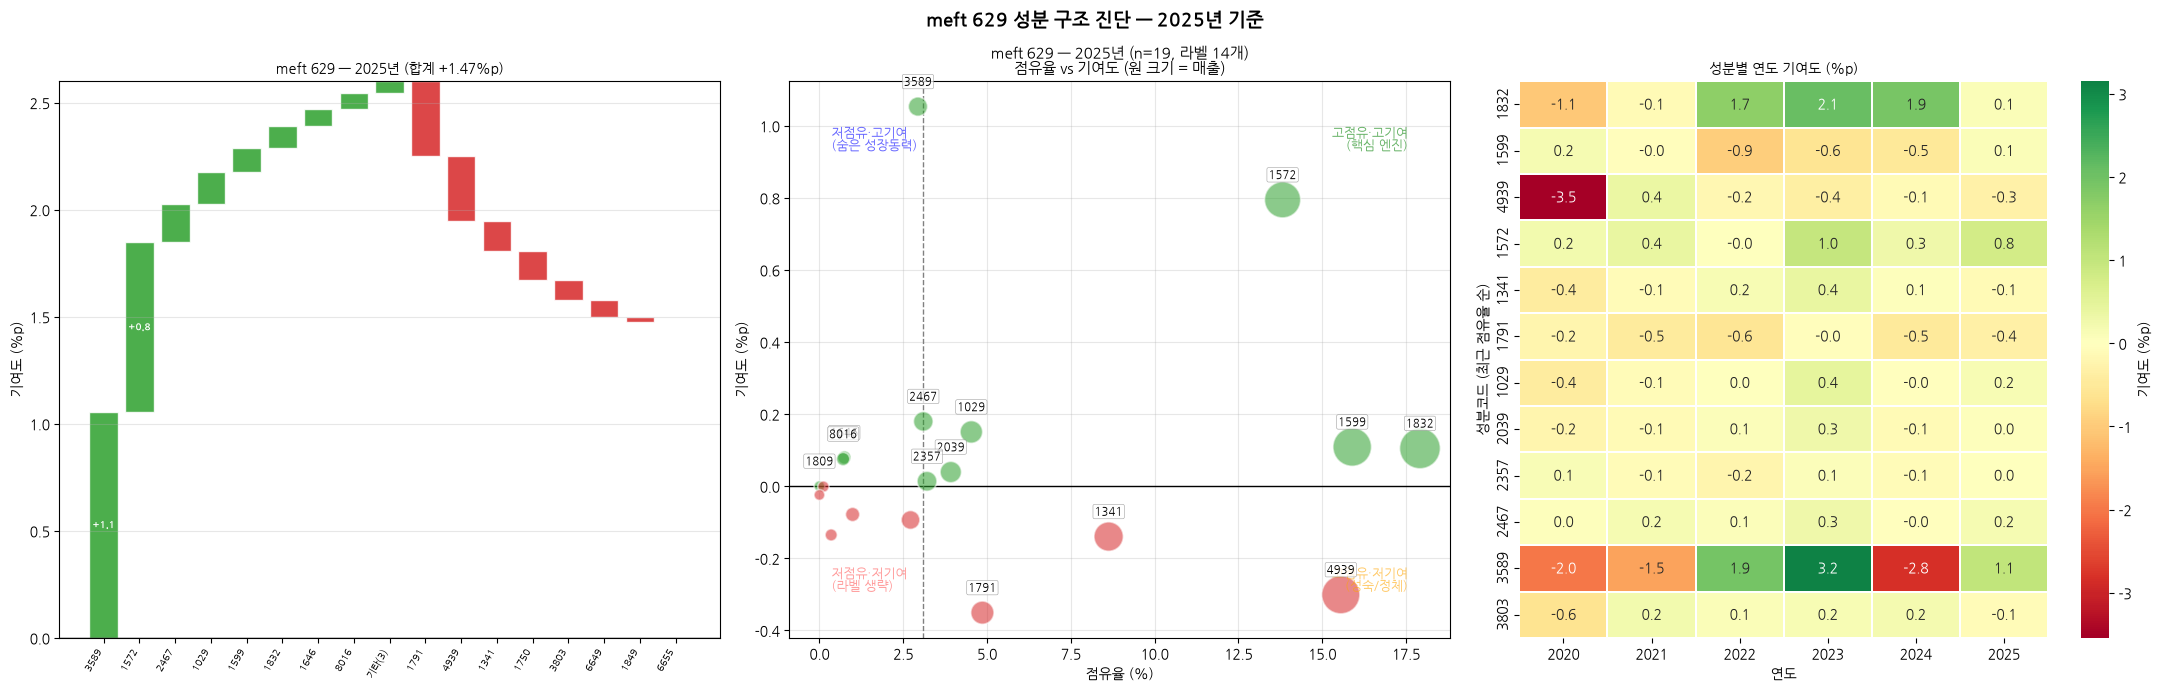

In [87]:
# 각 약효분류군 내부 성분 점유율
# for m in meft_all:
#     plot_meft_share(m, top_n=10, metric='share_in_meft')

last_year = int(contrib_meft_ing['year'].max())

fig, axes = plt.subplots(1, 3, figsize=(22, 7))

# (1) 기여도 워터폴
waterfall_meft(629, last_year, top_n=8, ax=axes[0])

# ② scatter — "각 성분이 어느 위치인가"
scatter_share_contrib(629, last_year, ax=axes[1])

# (2) 점유율 추이 Top 5
# plot_meft_share_year(629, top_n=5, ax=axes[1])

# (3) 기여도 히트맵 (성분 × 연도) ← 교체
sub = contrib_meft_ing[contrib_meft_ing['meft_no'] == 629]
top_ing = (sub[sub['year'] == last_year]
           .nlargest(12, 'share_in_meft')['WK_COMPN_4'].tolist())

hm = (sub[sub['WK_COMPN_4'].isin(top_ing)]
      .pivot_table(index='WK_COMPN_4', columns='year',
                   values='contrib_in_meft_pp') * 100)

# 최근 연도 점유율 순 정렬
order = (sub[sub['year'] == last_year]
         .set_index('WK_COMPN_4')['share_in_meft']
         .reindex(hm.index)
         .sort_values(ascending=False).index)
hm = hm.reindex(order)

sns.heatmap(hm, annot=True, fmt='.1f', cmap='RdYlGn',
            center=0, ax=axes[2], cbar_kws={'label': '기여도 (%p)'},
            linewidths=0.3)
axes[2].set_title('성분별 연도 기여도 (%p)', fontsize=10)
axes[2].set_xlabel('연도')
axes[2].set_ylabel('성분코드 (최근 점유율 순)')

fig.suptitle(f'meft 629 성분 구조 진단 — {last_year}년 기준',
             fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

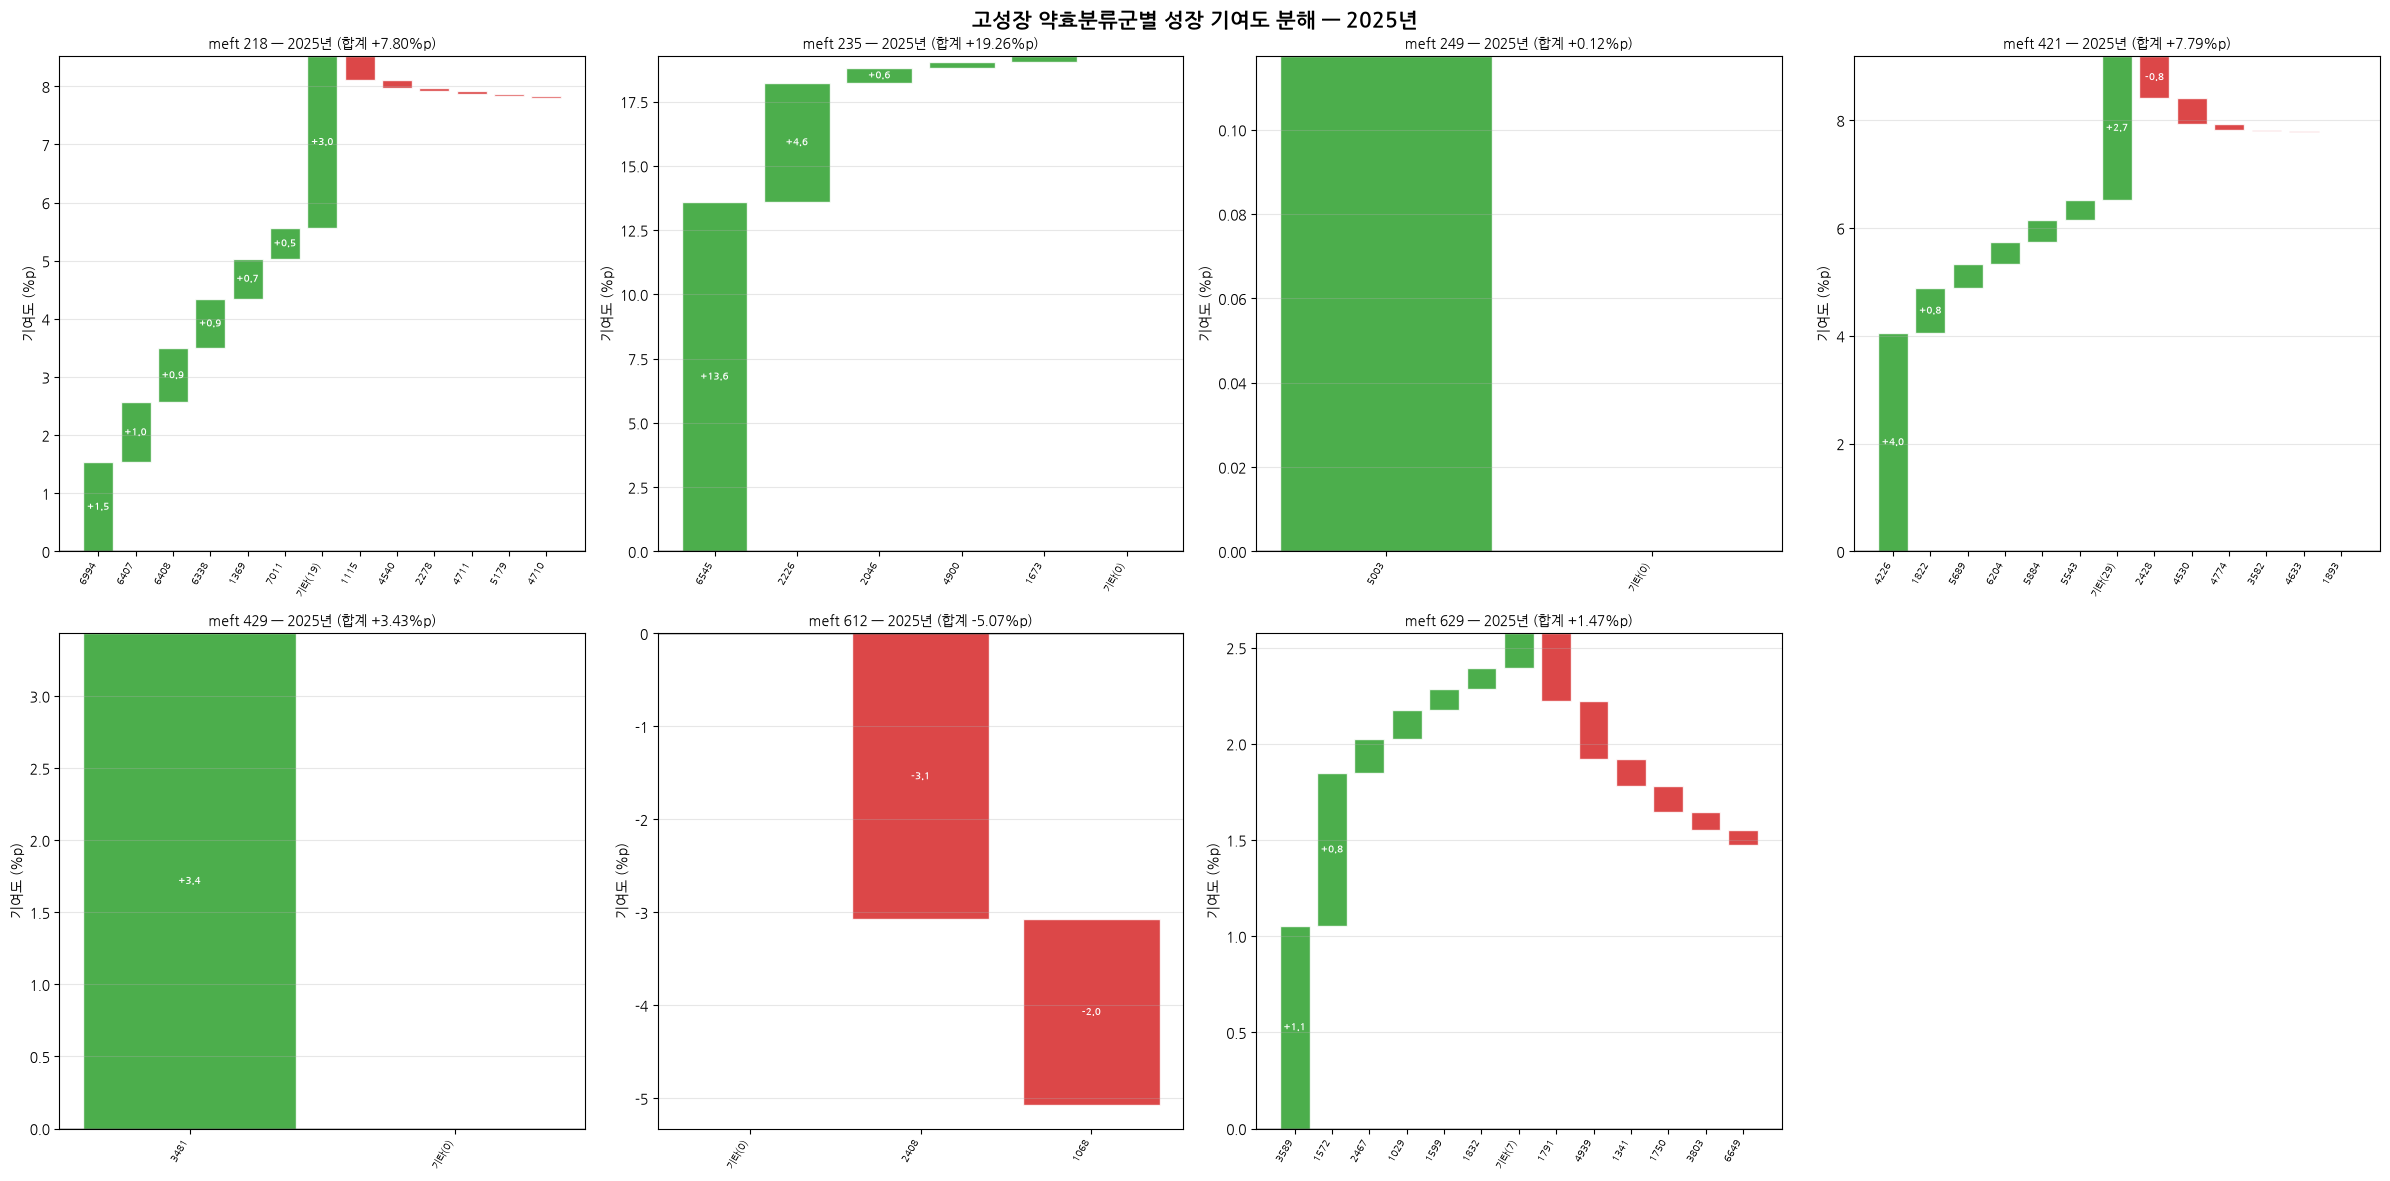

In [79]:
fig, axes = plt.subplots(2, 4, figsize=(24, 12))
axes = axes.flatten()

for i, m in enumerate(meft_all):
    waterfall_meft(m, last_year, top_n=6, ax=axes[i])

for j in range(len(meft_all), len(axes)):
    axes[j].axis('off')

fig.suptitle(f'고성장 약효분류군별 성장 기여도 분해 — {last_year}년',
             fontsize=15, fontweight='bold')
plt.tight_layout(); plt.show()

In [80]:
# 각 약효분류군 × 연도 성장률 매트릭스 (검증용)
growth_matrix = (contrib_meft_ing
                 .dropna(subset=['contrib_in_meft_pp'])
                 .groupby(['meft_no', 'year'])['contrib_in_meft_pp']
                 .sum()
                 .unstack('year') * 100)

print(growth_matrix.round(2))

year      2020    2021   2022   2023   2024   2025
meft_no                                           
218      14.53   21.19  10.43   9.60  10.97   7.80
235       2.53    9.18   5.90   9.77  13.92  19.26
249       3.98    3.71  -1.17   1.72   3.51   0.12
421       5.36    8.23   3.75  27.91  14.62   7.79
429        NaN  113.45   8.97   5.63   5.81   3.43
612     -12.72   -3.80   9.48  37.45 -13.61  -5.07
629      -8.92   -1.52   2.29   7.18  -1.77   1.47


In [81]:
# 성분 수 & 집중도 요약 (최근 연도)
summary = (contrib_meft_ing[contrib_meft_ing['year'] == last_year]
           .groupby('meft_no')
           .agg(
               meft_tot=('meft_tot', 'first'),
               n_codes=('WK_COMPN_4', 'nunique'),
               top1_share=('share_in_meft', 'max'),
               hhi=('share_in_meft', lambda s: (s**2).sum()),
           )
           .loc[meft_all])

print(summary.round(4))

             meft_tot  n_codes  top1_share     hhi
meft_no                                           
218      3.424445e+12       31      0.1695  0.0951
235      9.559062e+10        5      0.5493  0.3764
249      7.567887e+10        1      1.0000  1.0000
421      1.063651e+12       41      0.1249  0.0606
429      9.439073e+09        1      1.0000  1.0000
612      1.340288e+10        2      0.5117  0.5003
629      5.797239e+11       19      0.1792  0.1179


In [71]:
conc = (contrib_meft_ing
        .groupby(['meft_no', 'year'])
        .agg(
            top1_share=('share_in_meft', 'max'),
            hhi=('share_in_meft', lambda s: (s**2).sum()),
            n_codes=('WK_COMPN_4', 'nunique'),
        )
        .reset_index()
        .query('year == @last_year')
        .set_index('meft_no')
        .loc[meft_all])

print(conc.round(4))
# → meft 429, 249는 단일 성분(100%)
# → meft 235는 Top1 54.9% (집중)
# → meft 218은 31개 성분, Top1 17.0% (분산)

         year  top1_share     hhi  n_codes
meft_no                                   
218      2025      0.1695  0.0951       31
235      2025      0.5493  0.3764        5
249      2025      1.0000  1.0000        1
421      2025      0.1249  0.0606       41
429      2025      1.0000  1.0000        1
612      2025      0.5117  0.5003        2
629      2025      0.1792  0.1179       19


In [30]:
contrib = con.sql("""
    WITH c AS (
        SELECT WK_COMPN_4, STD_YYYYMM, SUM(PRSCRPTN_AMT) AS amt
        FROM grp GROUP BY ALL
    ),
    t AS (SELECT STD_YYYYMM, SUM(amt) AS tot FROM c GROUP BY 1)
    SELECT c.WK_COMPN_4, c.STD_YYYYMM, c.amt,
           c.amt - LAG(c.amt) OVER w                                      AS delta,
           (c.amt - LAG(c.amt) OVER w) / LAG(t.tot) OVER (ORDER BY c.STD_YYYYMM)  AS contrib_pp,
           c.amt / t.tot                                                  AS share
    FROM c JOIN t USING (STD_YYYYMM)
    WINDOW w AS (PARTITION BY c.WK_COMPN_4 ORDER BY c.STD_YYYYMM)
    ORDER BY c.STD_YYYYMM, delta DESC
""").df()
contrib.head()

,WK_COMPN_4,STD_YYYYMM,amt,delta,contrib_pp,share
0,1599,201901,7.806108e+09,NaN,NaN,0.030072
1,1572,201901,5.005233e+09,NaN,NaN,0.019282
2,1809,201901,4.967441e+08,NaN,NaN,0.001914
3,4812,201901,2.560833e+09,NaN,NaN,0.009865
4,2357,201901,1.245691e+09,NaN,NaN,0.004799


In [ ]:
decomp = con.sql("""
    WITH cm AS (    -- 성분×월 단위로 먼저 합산
        SELECT WK_COMPN_4, STD_YYYYMM, year,
               SUM(PATIENT_CNT)       AS pt,
               SUM(PRSCRPTN_TNDN_CNT) AS cnt,
               SUM(PRSCRPTN_TOT_USE)  AS qty,
               SUM(PRSCRPTN_AMT)      AS amt
        FROM grp GROUP BY ALL
    )
    SELECT year,
           SUM(pt)  AS pt_month,
           SUM(cnt) / SUM(pt)  AS cnt_per_pt,
           SUM(qty) / SUM(cnt) AS qty_per_cnt,
           SUM(amt) / SUM(qty) AS amt_per_qty,
           SUM(amt) / SUM(pt)  AS amt_per_pt
    FROM cm GROUP BY year ORDER BY year
""").df()
decomp.head()

,year,pt_month,cnt_per_pt,qty_per_cnt,amt_per_qty,amt_per_pt
0,2019,90586162.0,1.164954,27.778813,1022.970151,33104.373029
1,2020,92007080.0,1.155294,30.688700,990.177429,35106.223631
2,2021,100146251.0,1.142717,33.889046,952.999873,36905.488502
3,2022,106224192.0,1.136098,35.447266,931.228889,37502.045581
4,2023,116498080.0,1.130630,35.650658,952.664573,38399.710126


In [38]:
def drill(dim, codes_filter=None, metric="PRSCRPTN_AMT"):
    where = (f"WHERE WK_COMPN_4 IN ({','.join(repr(c) for c in codes_filter)})"
             if codes_filter else "")
    return con.sql(f"""
        SELECT
            {dim}, year, v as prscrptn_amt  ,
            v / SUM(v) OVER (PARTITION BY year) AS share_prscrptn_amt
        FROM (
            SELECT {dim}, year,
                   SUM(TRY_CAST({metric} AS DOUBLE)) AS v
            FROM grp
            {where}
            GROUP BY {dim}, year
        )
        ORDER BY {dim}, year
    """).df()

age   = drill("AGE_G")
sex   = drill("SEX_TYPE")
sido  = drill("SIDO")
inst  = drill("YOYANG_CLSFC_CD_ADJ")
inout = drill("OUT_IN_HOS")

In [39]:
age

,AGE_G,year,prscrptn_amt,share_prscrptn_amt
0,0,2019,3.896948e+10,0.012995
1,0,2020,3.376727e+10,0.010454
2,0,2021,3.922319e+10,0.010612
3,0,2022,3.764821e+10,0.009451
4,0,2023,4.520991e+10,0.010106
...,...,...,...,...
65,90,2021,4.074984e+10,0.011026
66,90,2022,4.848864e+10,0.012172
67,90,2023,5.644793e+10,0.012618
68,90,2024,6.714327e+10,0.013664


In [42]:
share = con.sql(f"""
    SELECT year,
           SUM(CASE WHEN WK_COMPN_4 IN ({code_sql}) THEN amt END) / SUM(amt) AS grp_share_amt
    FROM mkt GROUP BY year ORDER BY year
""").df()

share

,year,grp_share_amt
0,2019,0.206686
1,2020,0.218900
2,2021,0.231795
3,2022,0.230663
4,2023,0.233851
5,2024,0.240424
6,2025,0.245702


In [43]:
monthly = con.sql("""
    SELECT STD_YYYYMM, SUM(PRSCRPTN_AMT) AS amt, SUM(PRSCRPTN_TOT_USE) AS qty
    FROM grp GROUP BY 1 ORDER BY 1
""").df()


print(monthly.shape)
monthly.head()

(84, 3)


,STD_YYYYMM,amt,qty
0,201901,2.595843e+11,2.489182e+08
1,201902,2.109503e+11,2.004782e+08
2,201903,2.374227e+11,2.292675e+08
3,201904,2.540365e+11,2.495396e+08
4,201905,2.537026e+11,2.444424e+08
